## linear

### create a dataset

In [22]:
import torch
import numpy as np
import matplotlib.pyplot as plt

torch.manual_seed(42)

# build dataset
x = torch.randn(100, 2)     # data set
w = torch.tensor([2.0, 3.0])    # weight
b = 4.0     # bias

# build
y = x @ w + b + torch.randn(100) * 0.1


### define linear model

In [23]:
import torch.nn as nn

class LinearRegress(nn.Module):
    def __init__(self):
        super(LinearRegress, self).__init__()
        # define a linear that the input are 2 features and the output is 1
        self.linear = nn.Linear(2, 1)

    def forward(self, x):
        return self.linear(x)

# define the linear object
model = LinearRegress()
model.linear.weight
model.linear.bias

Parameter containing:
tensor([0.3518], requires_grad=True)

### define MSELoss

In [24]:
# 损失函数
criterion = nn.MSELoss()
# optimizer
optimizer = torch.optim.SGD(model.parameters(), lr=0.005)
# adam optimizer
# adam_opt = torch.optim.Adam(model.parameters(), lr=0.01)

### train model

In [32]:
num_epochs = 1000

for epoch in range(num_epochs):
    model.train()

    # predictions
    pre = model(x)  # forward
    los = criterion(pre.squeeze(), y)       # cal loss

    # backward
    optimizer.zero_grad()       # clear grad
    los.backward()      # cal grad
    optimizer.step()

    if (epoch + 1) % 100 == 0:
        # print(pre)
        print(f'Epoch {epoch + 1}, Loss {los.item():.4f}')

Epoch 100, Loss 0.0081
Epoch 200, Loss 0.0081
Epoch 300, Loss 0.0081
Epoch 400, Loss 0.0081
Epoch 500, Loss 0.0081
Epoch 600, Loss 0.0081
Epoch 700, Loss 0.0081
Epoch 800, Loss 0.0081
Epoch 900, Loss 0.0081
Epoch 1000, Loss 0.0081


### evaluate model

[[2.0096931 2.9986162]]
[4.020891]


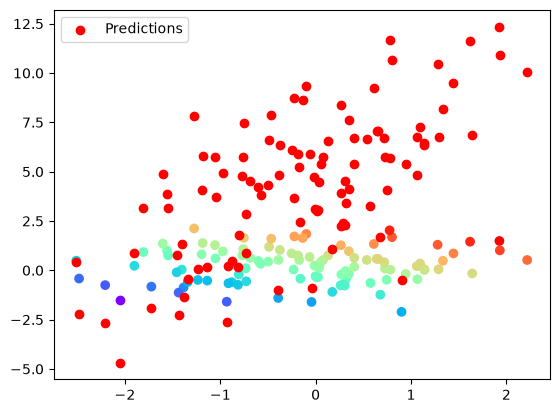

In [ ]:
pre_weight = model.linear.weight.data.numpy()
pre_bias = model.linear.bias.data.numpy()
print(pre_weight)
print(pre_bias)

with torch.no_grad():
    predictions = model(x)

plt.scatter(x[:, 0], x[:, 1], c=y, cmap='rainbow')
plt.scatter(x[:, 0], predictions, color='red', label='Predictions')
plt.legend()
plt.show()
